# 04 · Backtest con la coda reale degli ordini: Nasdaq ITCH (E3)

È la **stima principale** della tesi. Con i dati ITCH si sa quanti ordini ci sono davanti alla propria quota, quindi l'esecuzione si può simulare in modo realistico:

1. quando la strategia inserisce un ordine, questo si mette **in fondo alla coda** del suo prezzo, dietro tutti gli ordini già presenti;
2. se un ordine davanti viene cancellato, la coda si accorcia;
3. se un ordine davanti viene eseguito, la coda avanza;
4. la quota viene eseguita solo quando un'esecuzione arriva fino a lei, anche solo in parte.

Le tre regole L2 sono simulate sulla vista L2 dello **stesso flusso**, quindi la differenza tra i risultati dipende solo da come si decidono le esecuzioni.

**Dati:** calibrazione 30/01/2019, validazione 27/03/2019, test 5 giornate da luglio 2019 a gennaio 2020 (15 sessioni titolo-giorno, 09:30-16:00), 100 azioni per lato. **Costi Nasdaq di riferimento:** rebate di 0,20 cent/azione a chi fornisce liquidità, commissione di 0,30 cent/azione a chi la prende.

I termini tecnici sono spiegati nel **glossario** in fondo al notebook 06.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
test = R.load(ROOT, "test")                      # sessioni di test, strategia selezionata
validation = R.load(ROOT, "validation")          # griglia di parametri sulle sessioni di validazione
ablation = R.load(ROOT, "ablation")              # test ripetuto senza filtro di volatilità
variants = R.load(ROOT, "variants")              # varianti: inventory skew e imbalance
selected = R.load_json(ROOT, "selected_params")  # parametri scelti in validazione

def bias_figure(name, stats, unit, filename):
    """P&L per regola e rapporto tra esecuzioni L2 ed esecuzioni con la coda."""
    bias = R.fill_bias(test, name).median()
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
    R.bar_by_model(axes[0], stats, "P&L lordo medio per sessione (IC 95%)", unit)
    linthresh = 10 ** np.ceil(np.log10(max(1.0, abs(stats.loc["coda FIFO", "media"]))))
    axes[0].set_yscale("symlog", linthresh=linthresh, linscale=0.5)
    axes[1].bar([R.LABELS[m] for m in bias.index], bias, color=[R.COLORS[m] for m in bias.index], width=0.6)
    for k, v in enumerate(bias):
        axes[1].text(k, v * 1.08, f"{it(v, 1)}×", ha="center", va="bottom", color=R.INK)
    axes[1].axhline(1, color=R.INK, linewidth=0.8)
    axes[1].set(yscale="log", title="Esecuzioni rispetto alla coda FIFO (mediana)", ylim=(0.5, bias.max() * 3))
    axes[1].grid(axis="x", visible=False)
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches="tight")
    plt.show()
    return bias

stats = R.model_table(test, "itch")
queue = test[(test.dataset == "itch") & (test.model == "queue")]
q, t_ = stats.loc["coda FIFO"], stats.loc["touch"]
R.show_box("In breve", [
    f"Con la coda reale la strategia perde in media {it(-queue.net_nasdaq_base.mean())} USD netti per sessione, in {it((queue.net_nasdaq_base < 0).sum())} sessioni su {len(queue)}.",
    f"Con `touch`, sugli stessi dati, sembrerebbe guadagnare {it(t_['media'])} USD lordi per sessione.",
    "Il motivo principale della perdita è la selezione avversa: le quote vengono eseguite quando il prezzo sta per muoversi contro.",
])

> **In breve**
>
> - Con la coda reale la strategia perde in media 541 USD netti per sessione, in 15 sessioni su 15.
> - Con `touch`, sugli stessi dati, sembrerebbe guadagnare 112.108 USD lordi per sessione.
> - Il motivo principale della perdita è la selezione avversa: le quote vengono eseguite quando il prezzo sta per muoversi contro.

## 1. Scelta dei parametri (validazione)

P&L netto medio sulla giornata di validazione per ognuna delle 12 combinazioni, con la coda FIFO. Più scuro = risultato migliore (o meno negativo).

In [2]:
display(R.validation_grid(validation, "itch", "net_nasdaq_base").style.format("{:.0f}").background_gradient(cmap="Greys", axis=None))
display(Markdown(f"**Parametri scelti:** {R.params_text('itch', selected['itch']['params'])}."))

**Parametri scelti:** volatilità su una finestra di 120 secondi; si opera solo sotto il 50° percentile della volatilità di calibrazione; ogni quota resta nel book al massimo 30 s.

## 2. Risultati: coda reale contro regole L2

A sinistra il P&L lordo medio per sessione (scala simmetrica logaritmica, per far stare insieme valori molto diversi). A destra quante esecuzioni attribuisce ogni regola rispetto alla coda FIFO: 1× significa lo stesso numero.

,P&L medio per sessione (IC 95%),sessioni positive,sessioni
touch,112.108 (98.080; 129.037),100%,15
price-through,-534 (-807; -95),7%,15
cross,-1.401 (-1.936; -945),0%,15
coda FIFO,-570 (-695; -458),0%,15


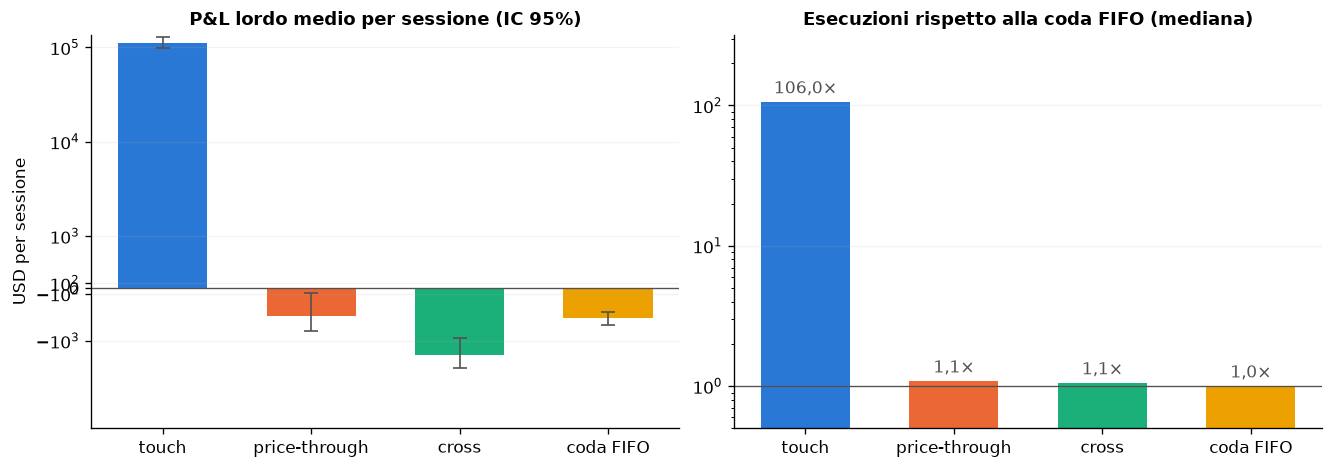

**Come leggerlo.** `touch` conta 106 volte le esecuzioni della coda e trasforma una perdita in un guadagno di 112.108 USD per sessione. `price-through` e `cross` hanno un numero di esecuzioni vicino alla coda (1,1× e 1,1×) ma sbagliano comunque il P&L: non sanno *quali* esecuzioni sarebbero toccate alla quota.

In [3]:
display(R.results_table(stats, 0))
bias = bias_figure("itch", stats, "USD per sessione", "itch_test.png")
display(Markdown(
    f"**Come leggerlo.** `touch` conta {it(bias['touch'])} volte le esecuzioni della coda e trasforma una perdita in un "
    f"guadagno di {it(t_['media'])} USD per sessione. `price-through` e `cross` hanno un numero di esecuzioni vicino "
    f"alla coda ({it(bias['price-through'], 1)}× e {it(bias['cross'], 1)}×) ma sbagliano comunque il P&L: non sanno "
    "*quali* esecuzioni sarebbero toccate alla quota."))

## 3. Perché la strategia perde

Scomposizione media per sessione (USD). Le commissioni sono negative per chi fornisce liquidità quando il rebate supera il costo: valori positivi in quella colonna sono un guadagno.

In [4]:
dec = R.decomposition(test, "itch", "fees_nasdaq_base")
display(R.decomposition_table(dec, 0))
display(R.fill_rates_table(R.fill_rates(test, "itch")))
d = dec.loc["coda FIFO"]
display(Markdown(
    f"**Come leggerlo.** Con la coda reale la strategia incassa {it(d['maker_edge'])} USD di spread per sessione, ma "
    f"perde {it(-d['inventory_pnl'])} USD perché dopo un'esecuzione il prezzo tende a muoversi contro la posizione "
    f"(**selezione avversa**) e {it(-d['liquidation_cost'])} USD per chiudere a mercato le coppie rimaste a metà. "
    "Solo una minoranza delle coppie viene eseguita su entrambi i lati."))

,spread incassato (edge maker),costo di liquidazione,movimento del prezzo sull'inventario,= P&L lordo,commissioni e rebate,= P&L netto
touch,112.494,-288,-98,112.108,26.978,139.086
price-through,478,-368,-644,-534,141,-393
cross,-840,-383,-178,-1.401,96,-1.305
coda FIFO,437,-269,-739,-570,30,-541


,coppie quotate,entrambi i lati eseguiti,un solo lato eseguito,nessun lato eseguito,con fill parziale
touch,1.018.516,99%,1%,0%,0%
price-through,14.747,48%,48%,4%,0%
cross,13.180,41%,54%,5%,0%
coda FIFO,10.990,26%,48%,26%,12%


**Come leggerlo.** Con la coda reale la strategia incassa 437 USD di spread per sessione, ma perde 739 USD perché dopo un'esecuzione il prezzo tende a muoversi contro la posizione (**selezione avversa**) e 269 USD per chiudere a mercato le coppie rimaste a metà. Solo una minoranza delle coppie viene eseguita su entrambi i lati.

## 4. Risultato per titolo e giornata (coda FIFO, USD netti)

In [5]:
display(queue.pivot_table(index="session", columns="symbol", values="net_nasdaq_base").round(0).astype(int))

symbol,AAPL,INTC,MSFT
session,,,
2019-07-30,-542,-355,-534
2019-08-30,-923,-368,-345
2019-10-30,-967,-380,-405
2019-12-30,-898,-343,-545
2020-01-30,-762,-401,-342


## 5. Il filtro di volatilità

La volatilità su ITCH è misurata **in secondi**: il midpoint viene campionato ogni secondo. Misurarla per messaggio darebbe stime falsate all'apertura, quando migliaia di messaggi non muovono il prezzo. Nel grafico, in grigio, i periodi in cui la strategia resta ferma.

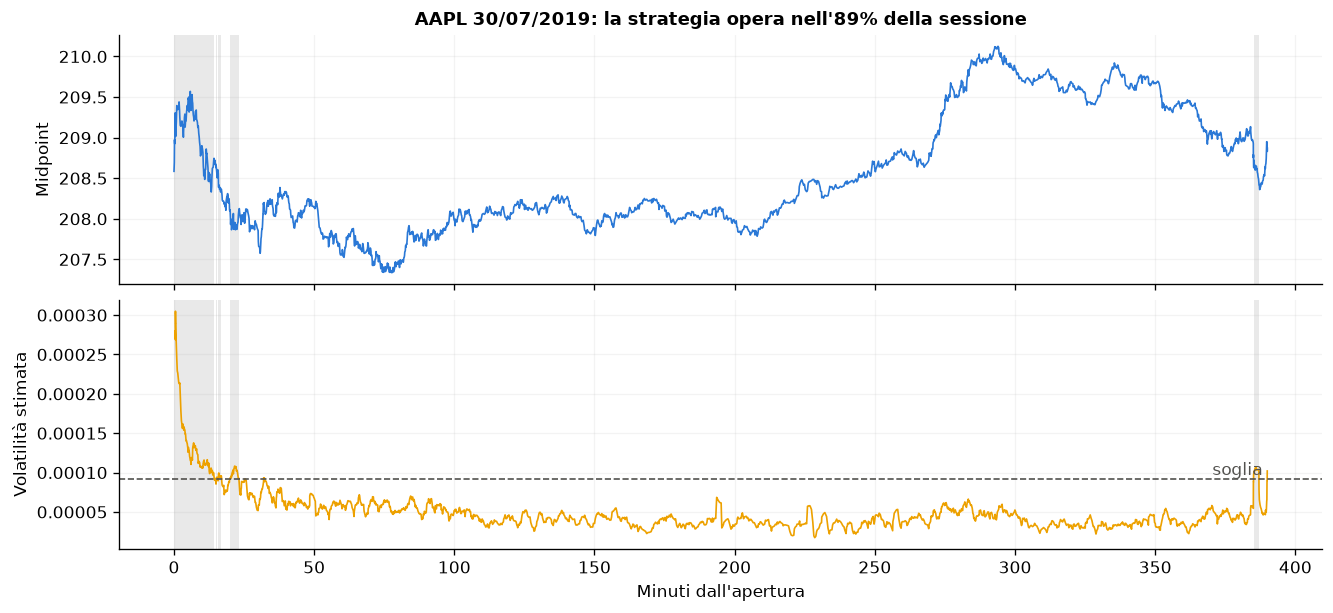

**Con filtro e sempre attiva** (P&L netto per sessione, USD; differenza appaiata sessione per sessione)

,con filtro,sempre attiva,differenza (IC 95%),sessioni migliori con filtro,tempo in cui opera
modello,,,,,
touch,139.086,171.576,-32.490 (-45.233; -21.171),0%,71%
price-through,-393,-413,20 (-296; 238),73%,71%
cross,-1.305,-1.786,481 (259; 762),100%,71%
coda FIFO,-541,-692,151 (60; 259),80%,71%


**Come leggerlo.** Il filtro ferma la strategia soprattutto nei primi minuti dopo l'apertura e nei picchi di volatilità. Riduce la perdita, ma non la elimina.

In [6]:
row = queue[(queue.session == "2019-07-30") & (queue.symbol == "AAPL")].iloc[0]
equity = pd.read_csv(ROOT / "results/runs/itch/2019-07-30_AAPL/queue/equity.csv")
minutes = (equity.timestamp - 34_200 * 10**9) / 6e10
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, layout="constrained")
R.plot_regime(axes, equity, row.volatility_threshold, minutes, None, "Minuti dall'apertura")
axes[0].set_title(f"AAPL 30/07/2019: la strategia opera {R.nel(row.active_share, 0)} della sessione")
fig.savefig(FIGURES / "itch_regime_volatilita.png", dpi=180, bbox_inches="tight")
plt.show()
display(Markdown("**Con filtro e sempre attiva** (P&L netto per sessione, USD; differenza appaiata sessione per sessione)"))
display(R.filter_table(R.filter_effect(test, ablation, "itch", "net_nasdaq_base"), 0))
display(Markdown(
    "**Come leggerlo.** Il filtro ferma la strategia soprattutto nei primi minuti dopo l'apertura e nei picchi di "
    "volatilità. Riduce la perdita, ma non la elimina."))

## 6. Varianti della strategia

Due estensioni, valutate sulle stesse sessioni con gli stessi parametri base:

* **inventory skew**: dopo un'esecuzione su un solo lato non chiude a mercato, ma lascia un ordine passivo solo sul lato che riduce la posizione;
* **filtro di imbalance**: quota solo quando il book è bilanciato e cancella una quota se lo squilibrio dei volumi indica che il prezzo sta per attraversarla.

In [7]:
display(R.variants_table(R.variant_effect(test, variants, "itch", "net_nasdaq_base", fee_column="fees_nasdaq_base"), 0))
for variant, info in selected["variants"]["itch"].items():
    display(Markdown(f"- **{R.VARIANT_LABELS[variant]}:** {R.params_text('itch', info['params'])}"))

,P&L netto medio (IC 95%),sessioni positive,differenza vs base (IC 95%),liquidazioni a mercato per sessione
variante,,,,
base,-541 (-660; -435),0%,—,392
inventory skew,-144 (-243; -68),13%,396 (298; 513),29
filtro di imbalance,-259 (-402; -132),0%,281 (224; 339),524
skew + imbalance,-71 (-145; -8),13%,470 (389; 559),25


- **filtro di imbalance:** si quota solo con imbalance |I| ≤ 0,3

- **inventory skew:** inventario smaltito con quote passive migliorate di 1 tick, liquidazione a mercato solo dopo 10 volte la durata di una quota

- **skew + imbalance:** inventario smaltito con quote passive al miglior prezzo corrente, liquidazione a mercato solo dopo 10 volte la durata di una quota; si quota solo con imbalance |I| ≤ 0,3